# Diabetic Retinopathy Stage Detection — Computer Vision Coursework



## 1. Setup

In [1]:

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Mounted at /content/drive
Running in Colab: True


In [2]:
import zipfile, os

DATASET_ZIP = "/content/drive/MyDrive/Computer Vision/archive (1).zip"
DATA_DIR = "/content/data"
PROJECT_DIR = "/content/dr_project"

if os.path.exists(DATASET_ZIP) and not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(DATASET_ZIP) as z:
        z.extractall(DATA_DIR)
    print("Extracted dataset to", DATA_DIR)

print(sorted(os.listdir(DATA_DIR)) if os.path.isdir(DATA_DIR) else "DATA_DIR not found yet")

Extracted dataset to /content/data
['Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']


In [3]:
from google.colab import files
uploaded = files.upload()

Saving dr_project.zip to dr_project.zip


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import zipfile
with zipfile.ZipFile("dr_project.zip") as z:
    z.extractall("/content")

import os
print(os.path.isdir("/content/dr_project/src"))

True


In [6]:
import os, sys

os.environ["DR_DATA_DIR"]   = "/content/data"
os.environ["DR_OUTPUT_DIR"] = "/content/outputs"
os.environ["DR_MODEL_DIR"]  = "/content/saved_models"

sys.path.append("/content/dr_project/src")

!pip install -q opencv-python-headless

In [7]:
import os
print(os.path.exists("/content/dr_project/src/config.py"))
print(os.listdir("/content/dr_project"))
import sys
print("/content/dr_project/src" in sys.path)

True
['README.md', 'notebooks', 'saved_models', 'requirements.txt', 'src', 'outputs']
True


In [8]:
import config, utils
utils.set_global_seed()
utils.check_gpu()
print("DATA_DIR =", config.DATA_DIR)
print("CLASS_NAMES =", config.CLASS_NAMES)

1 GPU(s) available: ['/physical_device:GPU:0']
DATA_DIR = /content/data
CLASS_NAMES = ['Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']


## 2. Dataset Justification


In [9]:
from data_preprocessing import build_dataframe, dataset_summary, stratified_split
import pandas as pd

df = build_dataframe()
summary = dataset_summary(df)
summary

{'total_images': 2750,
 'num_classes': 5,
 'class_counts': {'Healthy': 1000,
  'Mild DR': 370,
  'Moderate DR': 900,
  'Proliferate DR': 290,
  'Severe DR': 190},
 'imbalance_ratio': 5.26}

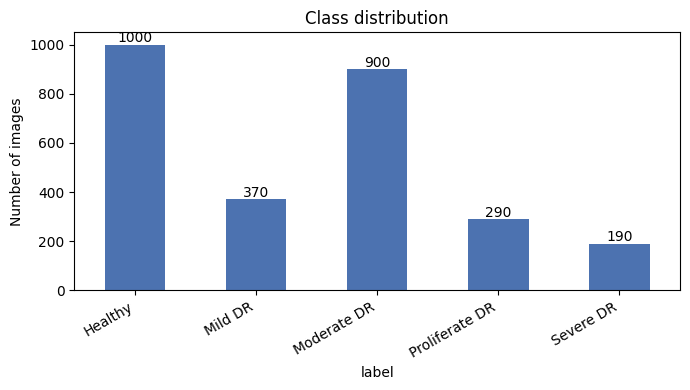

In [10]:
# Bar chart of how many images fall into each class.
# We reindex on config.CLASS_NAMES so the bars always appear in the same
# clinically-ordered sequence (Healthy -> Mild -> Moderate -> Proliferate ->
# Severe) rather than alphabetical or count order.
import matplotlib.pyplot as plt

counts = df["label"].value_counts().reindex(config.CLASS_NAMES)
fig, ax = plt.subplots(figsize=(7,4))
counts.plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Class distribution")
ax.set_ylabel("Number of images")

# Label each bar with its exact count
for i, v in enumerate(counts):
    ax.text(i, v + 10, str(v), ha="center")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{config.OUTPUT_DIR}/class_distribution.png", dpi=150)
plt.show()

In [11]:
# Stratified 70/15/15 train/val/test split (see stratified_split() in
# data_preprocessing.py) -- "stratified" means each split keeps the same
# class ratios as the full dataset, which matters because our classes are
# imbalanced (see the bar chart above).
train_df, val_df, test_df = stratified_split(df)
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

# Confirm the split preserved class ratios reasonably well.
train_df["label"].value_counts().reindex(config.CLASS_NAMES)

train=1924  val=413  test=413


,count
label,
Healthy,700
Mild DR,258
Moderate DR,630
Proliferate DR,203
Severe DR,133


## 3. Data Preprocessing


CLAHE contrast enhancement + retina cropping + edge enhancement + resize + normalise.
See `data_preprocessing.py` for full implementation details and rationale.

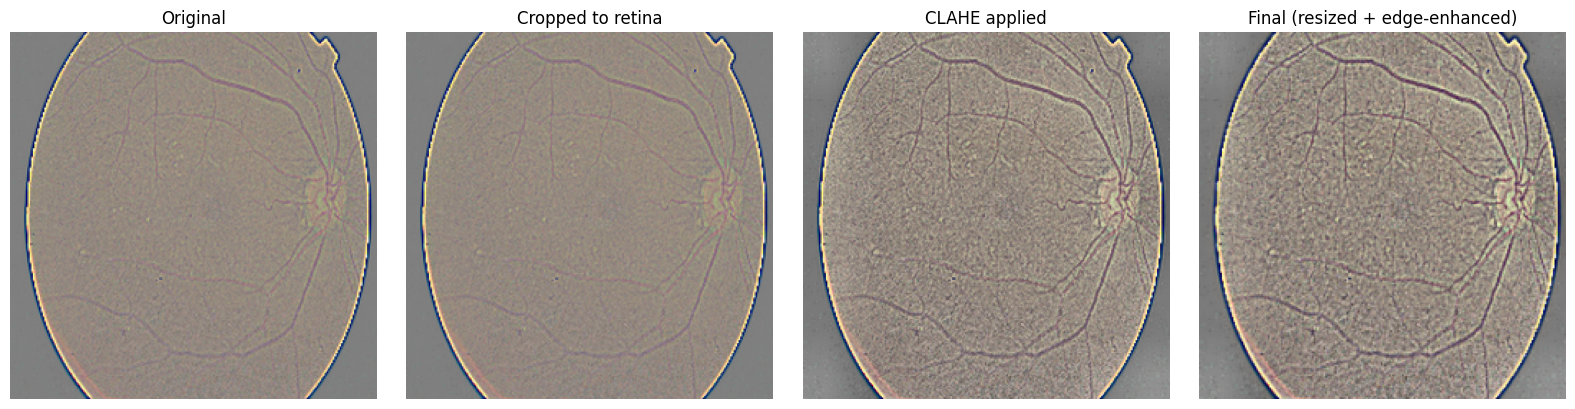

In [12]:
# Pick one real sample image and run it through each stage of the
# preprocessing pipeline separately, purely so we can visualise the effect
# of each step. In actual training, preprocess_image() does all of this
# in one call.
from data_preprocessing import preprocess_image, crop_to_circle_bounds, apply_clahe
import cv2

# cv2.imread loads as BGR by default, so convert to RGB before displaying
# with matplotlib (which expects RGB).
sample_row = df[df.label == "Moderate DR"].iloc[0]
orig = cv2.cvtColor(cv2.imread(sample_row.filepath), cv2.COLOR_BGR2RGB)
cropped = cv2.cvtColor(crop_to_circle_bounds(cv2.imread(sample_row.filepath)), cv2.COLOR_BGR2RGB)
clahe_img = cv2.cvtColor(apply_clahe(cv2.imread(sample_row.filepath)), cv2.COLOR_BGR2RGB)

# preprocess_image() runs the FULL pipeline (crop + CLAHE + edge enhancement
# + resize + normalise) and returns a float32 [0,1] array -- this is exactly
# what the model sees during training.
final = preprocess_image(sample_row.filepath)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes, [orig, cropped, clahe_img, final],
                           ["Original", "Cropped to retina", "CLAHE applied", "Final (resized + edge-enhanced)"]):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{config.OUTPUT_DIR}/preprocessing_demo.png", dpi=150)
plt.show()

## 4. Data Augmentation & Dataset Balancing


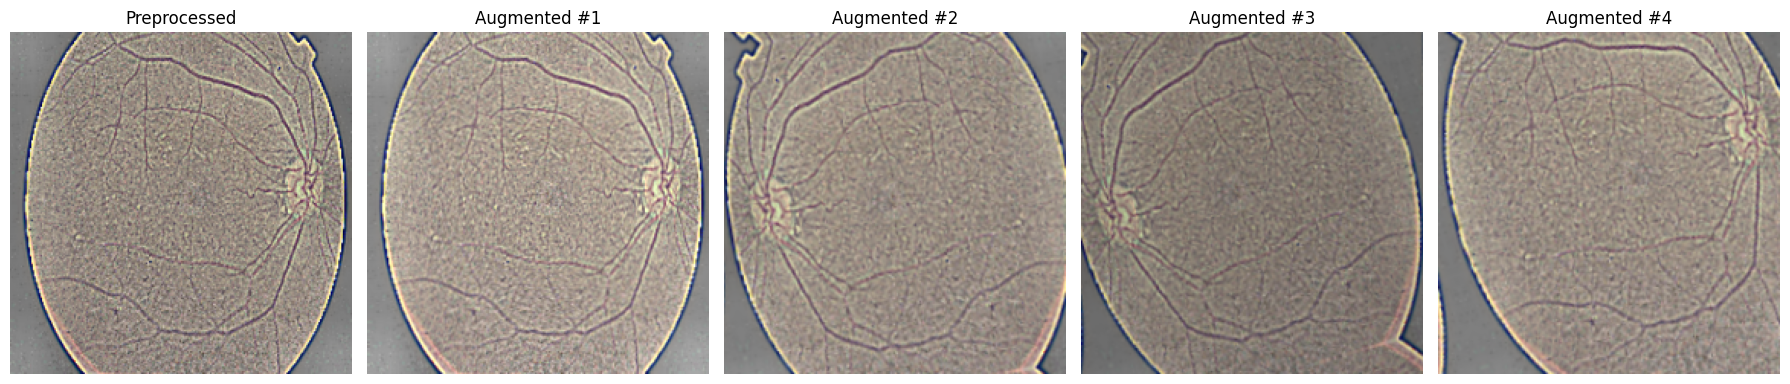

In [13]:
# Show what random augmentation looks like: take the already-preprocessed
# image from the previous cell and generate 4 independently-randomised
# augmented versions (different seed each time), the same way the training
# pipeline would generate a different augmentation of this image on every
# epoch it's seen.
from data_augmentation import augment_image_cv, get_class_weights

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(final); axes[0].set_title("Preprocessed"); axes[0].axis("off")
for i in range(1, 5):
    aug = augment_image_cv(final, seed=i)
    axes[i].imshow(aug); axes[i].set_title(f"Augmented #{i}"); axes[i].axis("off")
plt.tight_layout()
plt.savefig(f"{config.OUTPUT_DIR}/augmentation_demo.png", dpi=150)
plt.show()

In [14]:
# Inverse-frequency class weights: minority classes (e.g. Severe DR, only
# 190 images) get a HIGHER weight so mistakes on them cost the loss function
# more, counteracting the imbalance shown in the Section 1 bar chart.
class_weights = get_class_weights(train_df)

# Displayed as {class name: weight} instead of {index: weight} so it's
{config.CLASS_NAMES[k]: round(v, 3) for k, v in class_weights.items()}

{'Healthy': 0.55,
 'Mild DR': 1.491,
 'Moderate DR': 0.611,
 'Proliferate DR': 1.896,
 'Severe DR': 2.893}

## 5. CNN Architecture & Transfer Learning


In [15]:
# Build the transfer-learning model: a frozen, ImageNet-pretrained backbone
# (EfficientNetB0 by default -- see config.BACKBONE) plus a new randomly
# initialised classification head on top.
from model import build_model, unfreeze_for_fine_tuning, count_trainable_params

model, backbone = build_model()
model.summary() # full layer-by-layer architecture

# At this point only the head is trainable; the backbone is frozen, so this
# number should be small relative to the backbone's total parameter count.
print("Trainable params (phase 1, head only):", count_trainable_params(model))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DR_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout_2 (Dropout)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,184 (16.08 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Trainable params (phase 1, head only): 164613


## 6. Training Strategy & Experimental Design


Two-phase training: (1) frozen backbone, head only, (2) fine-tune the top
layers at a lower learning rate. Both phases use class weights,
EarlyStopping, ReduceLROnPlateau and ModelCheckpoint — see `train.py`.

In [16]:
# Build the actual tf.data pipelines used for training/evaluation.
# training=True enables on-the-fly augmentation (train set only); the
# validation and test sets are NOT augmented, since we want to measure
# performance on realistic, unmodified images.
from data_augmentation import build_tf_dataset

train_ds = build_tf_dataset(train_df, training=True)
val_ds = build_tf_dataset(val_df, training=False)
test_ds = build_tf_dataset(test_df, training=False)

In [17]:
# ---- PHASE 1: train the classification head only, backbone frozen ----
# Learning rate is relatively high (1e-3) since we're training randomly
# initialised weights from scratch and want them to converge quickly.
import tensorflow as tf
from train import make_callbacks

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=config.LEARNING_RATE_HEAD),
    loss="categorical_crossentropy", # standard for multi-class, one-hot-encoded labels
    metrics=["accuracy"],
)

# class_weight=class_weights applies the imbalance correction from the cell
# above. make_callbacks(...) attaches EarlyStopping, ReduceLROnPlateau and
# ModelCheckpoint -- see train.py for what each one does and why.
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=config.EPOCHS_HEAD,
    class_weight=class_weights,
    callbacks=make_callbacks("phase1_head"),
)

Epoch 1/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 793ms/step - accuracy: 0.4030 - loss: 1.4941
Epoch 1: val_loss improved from None to 0.98656, saving model to /content/saved_models/best_model_phase1_head.keras

Epoch 1: finished saving model to /content/saved_models/best_model_phase1_head.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step - accuracy: 0.4621 - loss: 1.3811 - val_accuracy: 0.6077 - val_loss: 0.9866 - learning_rate: 0.0010
Epoch 2/15
60/61 ━━━━━━━━━━━━━━━━━━━━ 0s 552ms/step - accuracy: 0.5384 - loss: 1.2666
Epoch 2: val_loss improved from 0.98656 to 0.95408, saving model to /content/saved_models/best_model_phase1_head.keras

Epoch 2: finished saving model to /content/saved_models/best_model_phase1_head.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 84s 634ms/step - accuracy: 0.5416 - loss: 1.2270 - val_accuracy: 0.6368 - val_loss: 0.9541 - learning_rate: 0.0010
Epoch 3/15
60/61 ━━━━━━━━━━━━━━━━━━━━ 0s 549ms/step - accuracy: 0.5902 - loss: 1.1298
Epoch 3: val_loss improved from 0.95408 to 0.93266, s

In [18]:
# ---- PHASE 2: fine-tune the top of the backbone ----
# unfreeze_for_fine_tuning() unfreezes only the top N backbone layers
# (BatchNorm layers stay frozen even within that block -- see model.py for
# why). The learning rate is dropped 100x (to 1e-5) so we nudge the
# pretrained weights gently instead of overwriting them.
from model import unfreeze_for_fine_tuning, count_trainable_params

unfreeze_for_fine_tuning(model, backbone, fine_tune_at=-60)   # was -40: unfreeze more of the backbone
print("Trainable params (phase 2):", count_trainable_params(model))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5),   # was 1e-5: too low to move much in 8 epochs
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# Give it more room before EarlyStopping cuts it off
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(f"{config.MODEL_DIR}/best_model_phase2_v2.keras",
                                        monitor="val_loss", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                      restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=4, min_lr=1e-8, verbose=1),
]

history_ft_v2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=callbacks,
)

Trainable params (phase 2, fine-tuning): 2202133
Epoch 1/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 725ms/step - accuracy: 0.6315 - loss: 1.0186
Epoch 1: val_loss improved from None to 0.88437, saving model to /content/saved_models/best_model_phase2_finetune.keras

Epoch 1: finished saving model to /content/saved_models/best_model_phase2_finetune.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 90s 988ms/step - accuracy: 0.6383 - loss: 1.0089 - val_accuracy: 0.6271 - val_loss: 0.8844 - learning_rate: 1.0000e-05
Epoch 2/20
60/61 ━━━━━━━━━━━━━━━━━━━━ 0s 556ms/step - accuracy: 0.6499 - loss: 1.0201
Epoch 2: val_loss improved from 0.88437 to 0.87062, saving model to /content/saved_models/best_model_phase2_finetune.keras

Epoch 2: finished saving model to /content/saved_models/best_model_phase2_finetune.keras
61/61 ━━━━━━━━━━━━━━━━━━━━ 40s 648ms/step - accuracy: 0.6336 - loss: 1.0206 - val_accuracy: 0.6465 - val_loss: 0.8706 - learning_rate: 1.0000e-05
Epoch 3/20
60/61 ━━━━━━━━━━━━━━━━━━━━ 0s 555ms/step - accuracy: 

In [19]:
# Save the final trained model to disk
import os
final_path = os.path.join(config.MODEL_DIR, "dr_final_model.keras")
model.save(final_path)
print("Saved:", final_path)

Saved: /content/saved_models/dr_final_model.keras


## 7. Model Evaluation & Performance Analysis


Saved /content/outputs/curves_phase1_head.png
Saved /content/outputs/curves_phase2_finetune.png


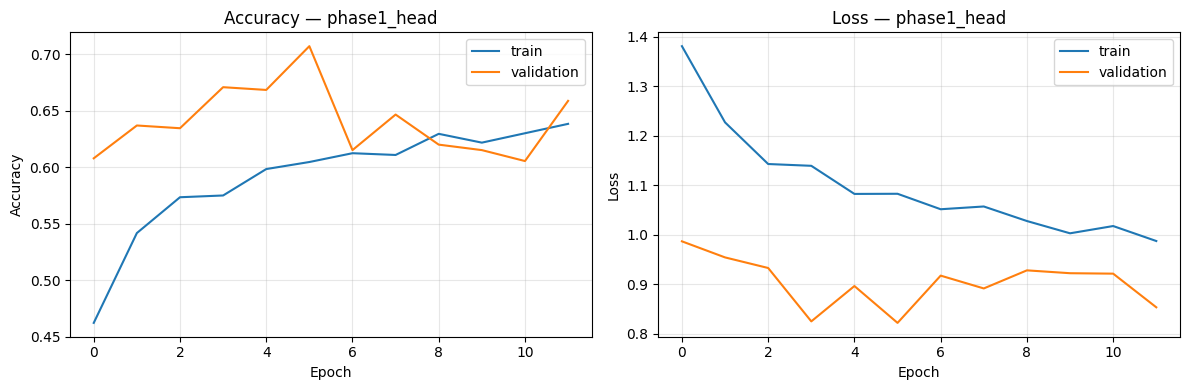

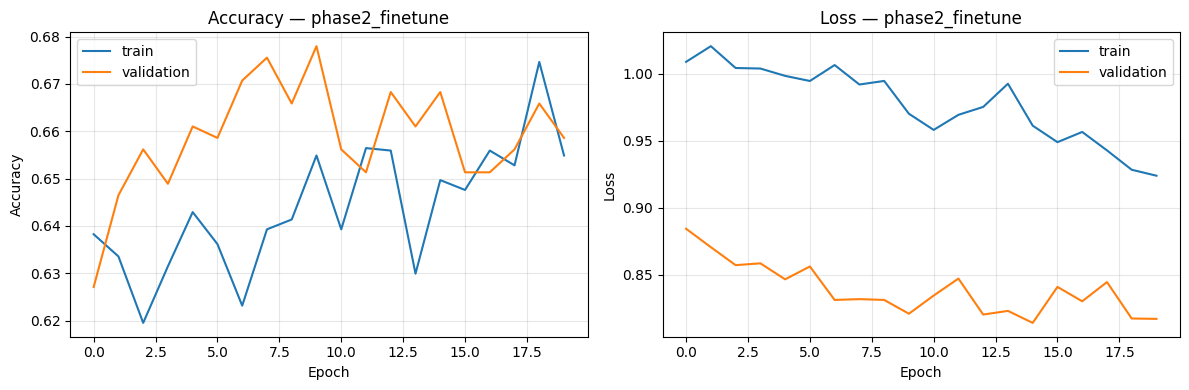

In [20]:
# Plot accuracy/loss curves for BOTH training phases separately -- comparing
# train vs. validation on each shows whether/where the model started
# overfitting (validation loss rising while training loss keeps falling).
from evaluate import (
    plot_training_curves, get_predictions, plot_confusion_matrix,
    get_classification_report, get_classification_report_dict,
    plot_per_class_metrics, most_confident_errors,
)

plot_training_curves(history_head.history, "phase1_head")
plot_training_curves(history_ft.history, "phase2_finetune")
plt.show()

Saved /content/outputs/confusion_matrix_counts.png


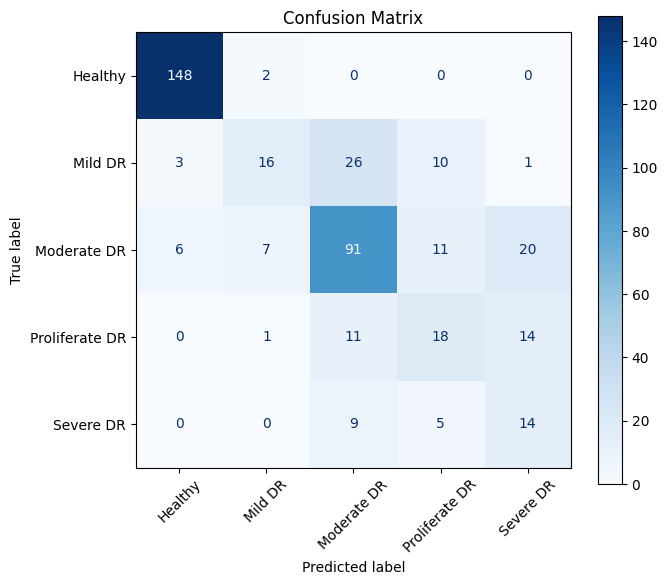

Saved /content/outputs/confusion_matrix_normalised.png


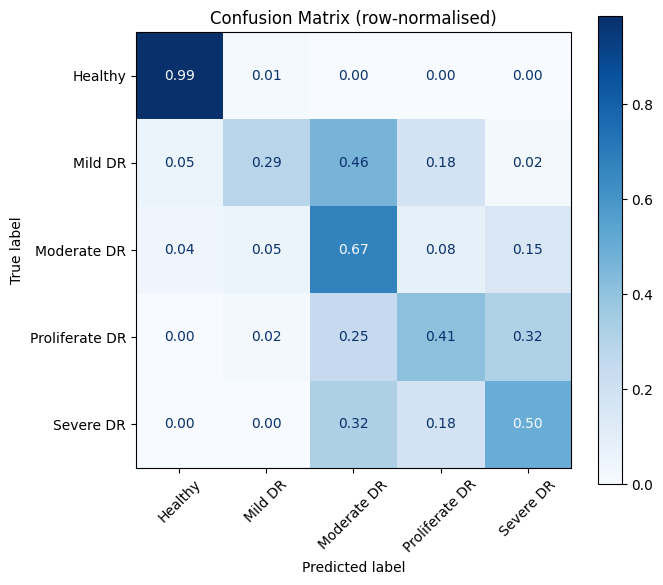

In [21]:
# Run the trained model over the held-out TEST set
y_true, y_pred, y_pred_probs = get_predictions(model, test_ds)

# Raw-count confusion matrix, then row-normalised (percentages) -- the
# normalised version is easier to read when classes have very different
# sizes, since raw counts alone are dominated by the biggest class.
plot_confusion_matrix(y_true, y_pred, normalize=False)
plt.show()
plot_confusion_matrix(y_true, y_pred, normalize=True)
plt.show()

                precision    recall  f1-score   support

       Healthy      0.943     0.987     0.964       150
       Mild DR      0.615     0.286     0.390        56
   Moderate DR      0.664     0.674     0.669       135
Proliferate DR      0.409     0.409     0.409        44
     Severe DR      0.286     0.500     0.364        28

      accuracy                          0.695       413
     macro avg      0.583     0.571     0.559       413
  weighted avg      0.706     0.695     0.690       413

Saved /content/outputs/classification_report.txt
Saved /content/outputs/per_class_metrics.png


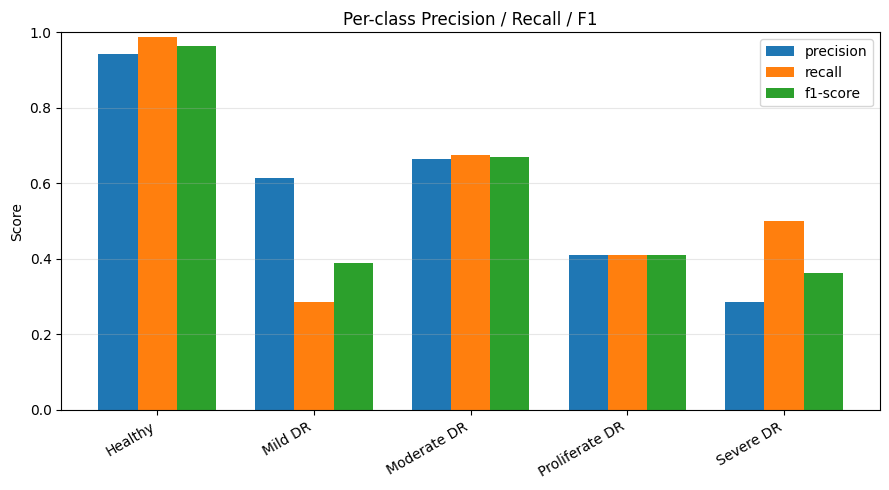

In [22]:
# Full precision/recall/F1 breakdown per class, plus macro and weighted
# averages. Macro-average matters most here since our classes are
# imbalanced -- it treats every class equally rather than letting the
# large Healthy/Moderate classes dominate the headline number.
report = get_classification_report(y_true, y_pred)
report_dict = get_classification_report_dict(y_true, y_pred)
plot_per_class_metrics(report_dict)
plt.show()

In [23]:
# List the 10 misclassified test images the model was MOST confident about
# being right
errors = most_confident_errors(y_true, y_pred, y_pred_probs, test_df, top_n=10)
pd.DataFrame(errors)

,filepath,true_label,predicted_label,confidence
0,/content/data/Mild DR/Mild_DR_277.png,Mild DR,Healthy,0.743100
1,/content/data/Proliferate DR/Proliferate DR_83...,Proliferate DR,Severe DR,0.710867
2,/content/data/Proliferate DR/Proliferate DR_10...,Proliferate DR,Severe DR,0.658350
3,/content/data/Mild DR/Mild_DR_157.png,Mild DR,Healthy,0.628870
4,/content/data/Proliferate DR/Proliferate DR_10...,Proliferate DR,Moderate DR,0.620953
5,/content/data/Proliferate DR/Proliferate DR_10...,Proliferate DR,Severe DR,0.613251
6,/content/data/Moderate DR/Moderate_DR_339.png,Moderate DR,Proliferate DR,0.594788
7,/content/data/Moderate DR/Moderate_DR_541.png,Moderate DR,Mild DR,0.581217
8,/content/data/Moderate DR/Moderate_DR_814.png,Moderate DR,Healthy,0.576149
9,/content/data/Mild DR/Mild_DR_324.png,Mild DR,Moderate DR,0.573263


In [24]:
import shutil
shutil.copytree("/content/outputs", "/content/drive/MyDrive/Computer Vision/dr_outputs", dirs_exist_ok=True)
shutil.copytree("/content/saved_models", "/content/drive/MyDrive/Computer Vision/dr_models", dirs_exist_ok=True)
print("Backed up to Drive")

Backed up to Drive


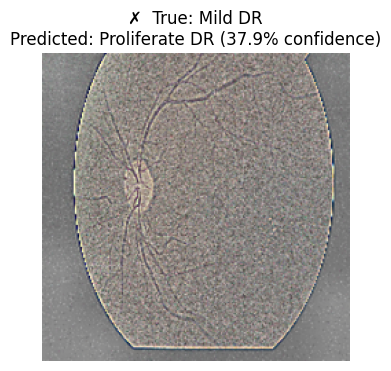

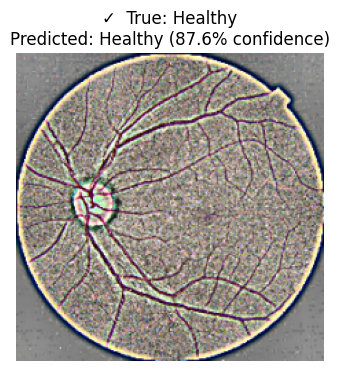

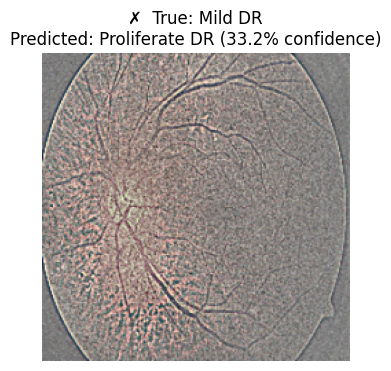

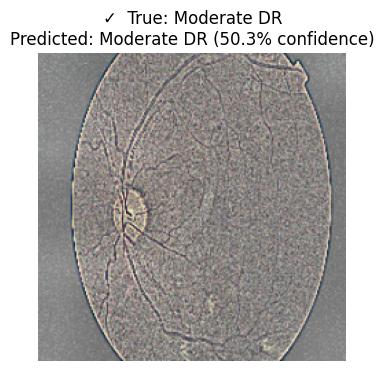

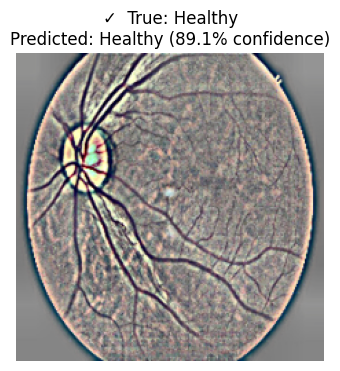

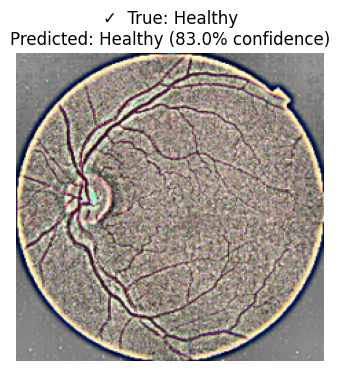

In [26]:
# ---- Prototype Demonstration: load the trained model and run live inference ----
import tensorflow as tf
import matplotlib.pyplot as plt
from data_preprocessing import preprocess_image
from config import CLASS_NAMES
import os

model = tf.keras.models.load_model(os.path.join(config.MODEL_DIR, "dr_final_model.keras"))

# Randomly sample 6 images from the held-out TEST set (never used in training
# or validation) -- random_state fixes which
# 6 images get picked, so the demo is reproducible if re-run.
sample_files = test_df.sample(6, random_state=7)

for _, row in sample_files.iterrows():
    # Run the SAME preprocessing pipeline used during training (crop, CLAHE,
    # edge enhancement, resize, normalise) -- the model must see inputs
    # prepared exactly the way it was trained on.
    img = preprocess_image(row["filepath"])

    # model.predict expects a batch, so add a batch dimension with img[None, ...]
    # (shape becomes (1, 224, 224, 3)). [0] then pulls the single prediction
    # back out of that batch of size 1.
    pred = model.predict(img[None, ...], verbose=0)[0]

    # pred is a softmax probability vector over the 5 classes; argmax() picks
    # the class with the highest predicted probability.
    pred_class = CLASS_NAMES[pred.argmax()]

    # Quick visual correct/incorrect marker.
    correct = "✓" if pred_class == row["label"] else "✗"

    # Display the image with true label, predicted label, and the model's
    # confidence (the softmax probability of its chosen class) in the title.
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"{correct}  True: {row['label']}\nPredicted: {pred_class} ({pred.max():.1%} confidence)")
    plt.axis("off")
    plt.show()